# EDA дорожных повреждений RDD2022

Считаем изображения и рамки по разбиениям, странам и классам. Рамки записаны как `[x, y, ширина, высота]` в пикселях. Метаданные анализируем целиком, сами изображения проверяем на подвыборке.

In [1]:
from hashlib import sha256
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Rectangle

root = Path("..") if Path.cwd().name == "notebooks" else Path(".")
data = root / "data" / "rdd"
splits = ["train", "valid", "test"]
labels = {0: "D00", 1: "D10", 2: "D20", 3: "D40"}
countries = {"China": "Китай", "Czech": "Чехия", "India": "Индия",
             "Japan": "Япония", "Norway": "Норвегия", "United": "США"}

parts = []
for split, count in zip(splits, [9, 2, 2]):
    for number in range(count):
        folder = f"data/images/{split}/shard_{number:03d}"
        part = pd.read_json(data / folder / "metadata.jsonl", lines=True)
        parts.append(part.assign(split=split, path=folder + "/" + part["file_name"]))

images = pd.concat(parts, ignore_index=True)
images["country"] = images["file_name"].str.split("_").str[0].map(countries)
images[["split", "country", "file_name", "objects"]].head()

,split,country,file_name,objects
0,train,Китай,China_Drone_000001.jpg,"{'bbox': [[14, 70, 184, 29], [95, 114, 25, 158..."
1,train,Китай,China_Drone_000002.jpg,"{'bbox': [[12, 214, 56, 297], [60, 1, 52, 211]..."
2,train,Китай,China_Drone_000003.jpg,"{'bbox': [[9, 467, 195, 22], [199, 304, 313, 4..."
3,train,Китай,China_Drone_000005.jpg,"{'bbox': [[1, 266, 210, 29], [131, 200, 31, 29..."
4,train,Китай,China_Drone_000009.jpg,"{'bbox': [[223, 1, 28, 166], [166, 171, 26, 34..."


## Сколько изображений и повреждений

Кадры с пустой аннотацией могут содержать дефекты вне четырёх целевых классов. В таблице считаем их как кадры без целевых рамок.

In [2]:
annotations = pd.json_normalize(images["objects"])
images["boxes"] = annotations["bbox"].str.len()
images["no_target"] = images["boxes"].eq(0)

images.groupby("split").agg(
    images=("file_name", "size"),
    boxes=("boxes", "sum"),
    no_target=("no_target", "sum")
).reindex(splits)

,images,boxes,no_target
split,,,
train,26869,41667,8967
valid,5758,8776,2015
test,5758,8724,1973


In [3]:
paired = images[["split", "path", "country"]].join(annotations)
paired = paired.explode(["bbox", "categories"]).dropna(subset=["bbox"]).reset_index(drop=True)
boxes = paired.drop(columns=["bbox", "categories"]).join(
    pd.DataFrame(paired["bbox"].tolist(), columns=["x", "y", "width", "height"])
)
boxes["class"] = paired["categories"].map(labels)
class_counts = pd.crosstab(boxes["split"], boxes["class"]).reindex(splits)
class_counts

class,D00,D10,D20,D40
split,,,,
train,18201,8386,7526,7554
valid,3890,1769,1553,1564
test,3925,1675,1537,1587


In [4]:
country_counts = pd.crosstab(images["country"], images["split"])[splits]
country_counts.assign(total=country_counts.sum(axis=1)).sort_values("total", ascending=False)

split,train,valid,test,total
country,,,,
Япония,7432,1550,1524,10506
Норвегия,5708,1256,1197,8161
Индия,5368,1172,1166,7706
США,3348,704,753,4805
Китай,3051,645,682,4378
Чехия,1962,431,436,2829


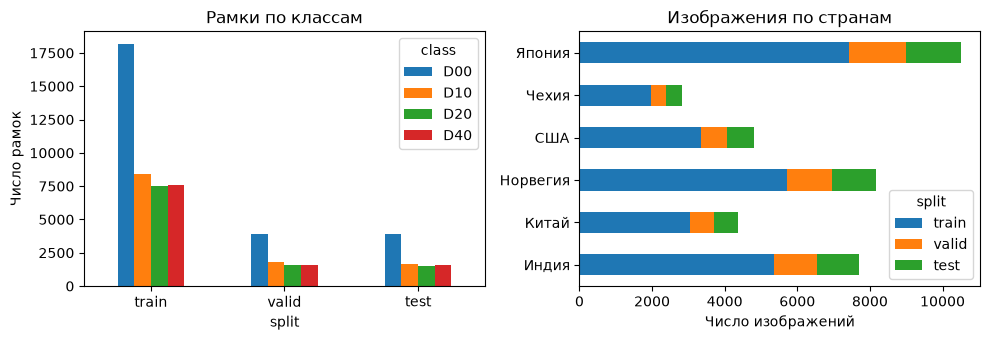

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
class_counts.plot.bar(ax=axes[0], rot=0, title="Рамки по классам")
axes[0].set_ylabel("Число рамок")
country_counts.plot.barh(ax=axes[1], stacked=True, title="Изображения по странам")
axes[1].set_xlabel("Число изображений")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

In [6]:
images_with_class = boxes.drop_duplicates(["path", "class"])
pd.crosstab(images_with_class["country"], images_with_class["class"])

class,D00,D10,D20,D40
country,,,,
Индия,1109,60,1758,1056
Китай,2453,1761,750,805
Норвегия,2518,1006,322,0
США,3907,2342,739,0
Чехия,764,300,129,0
Япония,2797,2240,4714,5579


D00 — продольная трещина, D10 — поперечная трещина, D20 — сетка трещин, D40 — яма.

In [7]:
images.groupby("split")["boxes"].describe(percentiles=[0.5, 0.95, 0.99]).reindex(splits).round(2)

,count,mean,std,min,50%,95%,99%,max
split,,,,,,,,
train,26869.0,1.55,1.95,0.0,1.0,5.0,8.0,44.0
valid,5758.0,1.52,1.99,0.0,1.0,5.0,8.0,34.0
test,5758.0,1.52,1.92,0.0,1.0,5.0,8.0,26.0


## Повторные рамки и пересечения по именам

Проверяем повтор одной и той же рамки в файле, неизвестные классы, пропуски и пересечение имён изображений между разбиениями.

In [8]:
invalid_box = (
    boxes[["x", "y"]].lt(0).any(axis=1)
    | boxes[["width", "height"]].le(0).any(axis=1)
    | boxes[["x", "y", "width", "height", "class"]].isna().any(axis=1)
)
repeated_box = boxes.duplicated(["path", "x", "y", "width", "height", "class"])
same_name = images.groupby("file_name")["split"].nunique().gt(1)
print("Рамки с пропусками или неверными значениями:", invalid_box.sum())
print("Повторные рамки сверх первого экземпляра:", repeated_box.sum())
print("Имена файлов в нескольких разбиениях:", same_name.sum())
boxes.loc[repeated_box, ["split", "path", "class", "x", "y", "width", "height"]]

Рамки с пропусками или неверными значениями: 0
Повторные рамки сверх первого экземпляра: 3
Имена файлов в нескольких разбиениях: 0


,split,path,class,x,y,width,height
18883,train,data/images/train/shard_004/Japan_006916.jpg,D40,1,383,145,122
24391,train,data/images/train/shard_005/Japan_011427.jpg,D40,9,387,187,204
45513,valid,data/images/valid/shard_001/Japan_006536.jpg,D40,468,44,131,75


## Размеры изображений и границы рамок

Подвыборка содержит 54 кадра, по три на каждую пару «страна × разбиение». Хеши декодированных пикселей используются для проверки точных совпадений в подвыборке.

In [9]:
frames = pd.read_csv(root / "rdd_frames.csv")
audit_paths = frames.loc[frames["role"].eq("audit"), "path"]
sizes = []
for path in audit_paths:
    pixels = plt.imread(data / path)
    height, width = pixels.shape[:2]
    sizes.append((path, width, height, sha256(pixels.tobytes()).hexdigest()))

sample = pd.DataFrame(sizes, columns=["path", "image_width", "image_height", "pixel_hash"])
sample = sample.merge(images[["path", "split"]], on="path")
sample["aspect_ratio"] = sample["image_width"] / sample["image_height"]
exact_duplicates = sample.groupby(["image_width", "image_height", "pixel_hash"])["split"].nunique()
print("Совпавшие изображения в разных разбиениях подвыборки:", exact_duplicates.gt(1).sum())
sample[["image_width", "image_height", "aspect_ratio"]].describe().round(2)

Совпавшие изображения в разных разбиениях подвыборки: 0


,image_width,image_height,aspect_ratio
count,54.00,54.00,54.00
mean,1163.41,851.56,1.15
std,1243.07,538.87,0.35
min,512.00,512.00,1.00
25%,600.00,600.00,1.00
50%,620.00,620.00,1.00
75%,720.00,720.00,1.00
max,4040.00,2044.00,1.99


Рамки за границами изображения: 0


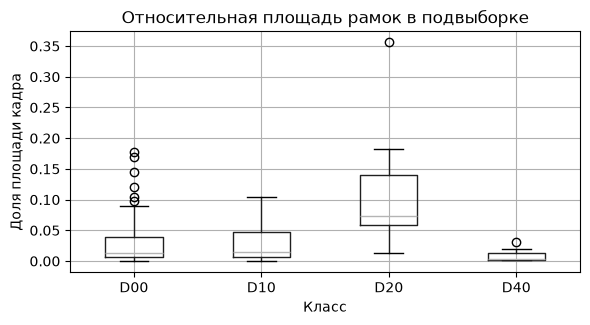

In [10]:
sample_boxes = boxes.merge(sample[["path", "image_width", "image_height"]], on="path")
outside = (
    (sample_boxes["x"] + sample_boxes["width"]).gt(sample_boxes["image_width"])
    | (sample_boxes["y"] + sample_boxes["height"]).gt(sample_boxes["image_height"])
)
print("Рамки за границами изображения:", outside.sum())
sample_boxes["area_share"] = (
    sample_boxes["width"] * sample_boxes["height"]
    / (sample_boxes["image_width"] * sample_boxes["image_height"])
)
sample_boxes.boxplot(column="area_share", by="class", figsize=(6, 3.5))
plt.suptitle("")
plt.title("Относительная площадь рамок в подвыборке")
plt.xlabel("Класс")
plt.ylabel("Доля площади кадра")
plt.tight_layout()
plt.show()

## Примеры разметки

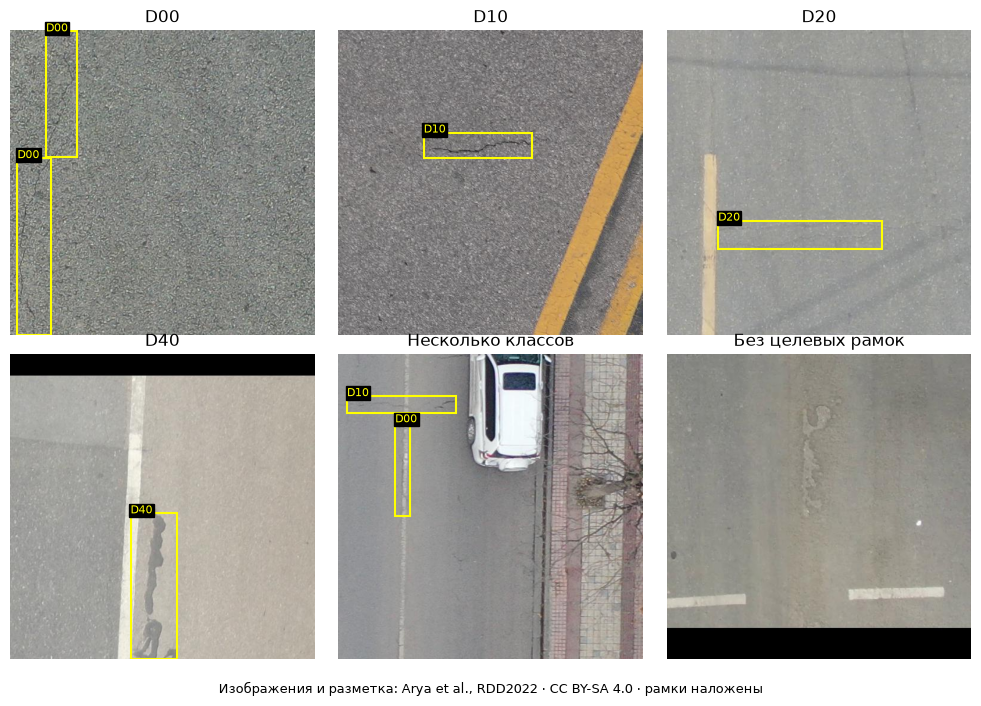

In [11]:
examples = frames.loc[frames["role"].eq("example")]
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, row in zip(axes.flat, examples.itertuples(index=False)):
    ax.imshow(plt.imread(data / row.path))
    ax.set_title(row.title)
    ax.axis("off")
    for _, box in boxes.loc[boxes["path"].eq(row.path)].iterrows():
        ax.add_patch(Rectangle((box["x"], box["y"]), box["width"], box["height"],
                               fill=False, edgecolor="yellow", linewidth=1.5))
        ax.text(box["x"], box["y"], box["class"], color="yellow", fontsize=8,
                bbox={"facecolor": "black", "pad": 1})
fig.supxlabel("Изображения и разметка: Arya et al., RDD2022 · CC BY-SA 4.0 · рамки наложены",
              fontsize=9)
plt.tight_layout()
plt.show()

## Выводы

- В наборе 38 385 изображений и 59 167 рамок. На 33,8% изображений нет целевых рамок. В train продольные трещины D00 дают 43,7% рамок.
- Больше всего кадров снято в Японии и Норвегии. При проверке качества модели стоит учитывать различия между странами.
- В метаданных есть три повторные рамки. Все 54 изображения из подвыборки открылись. Рамок за границами и пиксельных совпадений между разбиениями на этой подвыборке нет. Соседние кадры одного маршрута могут оказаться в разных разбиениях.